In [56]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [57]:
url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
df = pd.read_csv(url)

In [58]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [59]:
df.head()


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [60]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [61]:
#df['SeniorCitizen'].unique()

df['SeniorCitizen'].value_counts()

SeniorCitizen
0    5901
1    1142
Name: count, dtype: int64

In [62]:
df['SeniorCitizen'].value_counts(normalize=True)

SeniorCitizen
0    0.837853
1    0.162147
Name: proportion, dtype: float64

In [63]:
print(df.nunique())

customerID          7043
gender                 2
SeniorCitizen          2
Partner                2
Dependents             2
tenure                73
PhoneService           2
MultipleLines          3
InternetService        3
OnlineSecurity         3
OnlineBackup           3
DeviceProtection       3
TechSupport            3
StreamingTV            3
StreamingMovies        3
Contract               3
PaperlessBilling       2
PaymentMethod          4
MonthlyCharges      1585
TotalCharges        6531
Churn                  2
dtype: int64


In [64]:
# plot pie chart to see unique values share in gender, SeniorCitizen, Partner, Dependents, PhoneService           2
# MultipleLines, InternetService, OnlineSecurity, OnlineBackup, DeviceProtection, TechSupport, StreamingTV, 
# StreamingMovies, Contract, PaperlessBilling, PaymentMethod

all_cols = df.columns.to_list()

to_remove= {"customerID", "tenure", "MonthlyCharges","TotalCharges", "Churn"}

categorical_features = [col for col in all_cols if col not in to_remove]

for cat_feature in categorical_features:
    print(df[cat_feature].value_counts(normalize = True))


gender
Male      0.504756
Female    0.495244
Name: proportion, dtype: float64
SeniorCitizen
0    0.837853
1    0.162147
Name: proportion, dtype: float64
Partner
No     0.516967
Yes    0.483033
Name: proportion, dtype: float64
Dependents
No     0.700412
Yes    0.299588
Name: proportion, dtype: float64
PhoneService
Yes    0.903166
No     0.096834
Name: proportion, dtype: float64
MultipleLines
No                  0.481329
Yes                 0.421837
No phone service    0.096834
Name: proportion, dtype: float64
InternetService
Fiber optic    0.439585
DSL            0.343746
No             0.216669
Name: proportion, dtype: float64
OnlineSecurity
No                     0.496663
Yes                    0.286668
No internet service    0.216669
Name: proportion, dtype: float64
OnlineBackup
No                     0.438450
Yes                    0.344881
No internet service    0.216669
Name: proportion, dtype: float64
DeviceProtection
No                     0.439443
Yes                    0.34388

In [65]:
print(categorical_features)

['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


In [66]:
# gen_prop = df['gender'].value_counts(normalize=True)
# left = 0

# for category, proportion in gen_prop.items():
#     plt.barh(
#         y=0,
#         width=proportion,
#         left=left,
#         height = 0.8
#     )

#     left += proportion


# plt.xlim(0, 1)
# plt.ylim(-1, 1)
# plt.yticks([0], ['Gender'])
# plt.show()




In [67]:
feature_segments = {
    "Demographics": [
        'gender',
        'SeniorCitizen',
        'Partner',
        'Dependents'
    ],

    "Communication Services": [
        'PhoneService',
        'MultipleLines',
        'InternetService'
    ],

    "Security Services": [
        'OnlineSecurity',
        'OnlineBackup',
        'DeviceProtection',
        'TechSupport'
    ],

    "Entertainment Services": [
        'StreamingTV',
        'StreamingMovies'
    ],

    "Payment Features": [
        'Contract',
        'PaperlessBilling',
        'PaymentMethod'
    ]
}

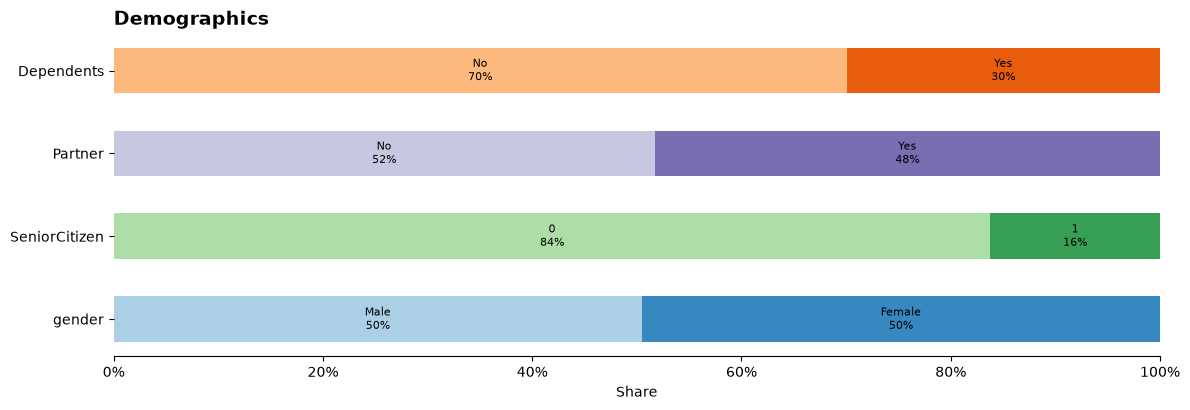

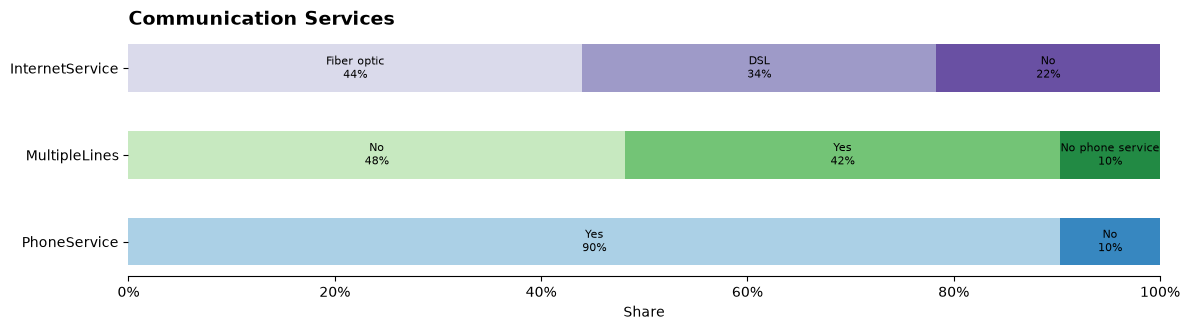

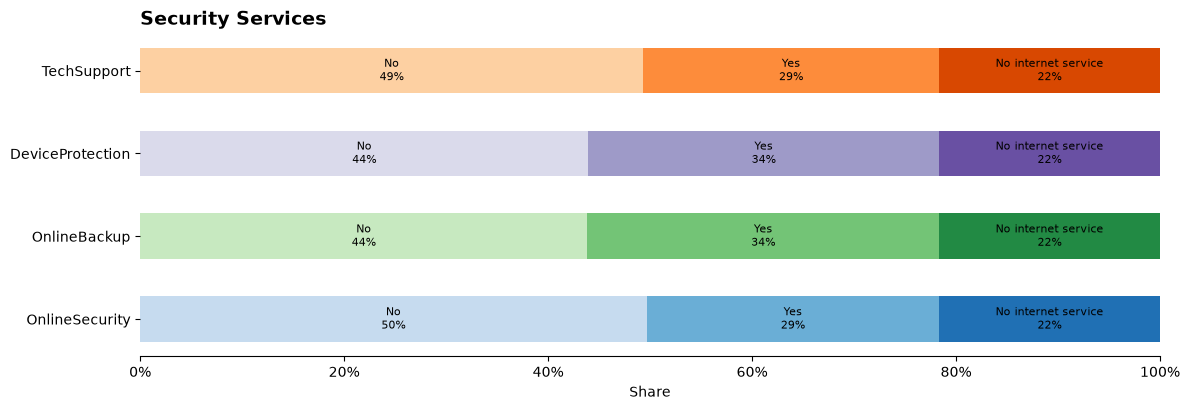

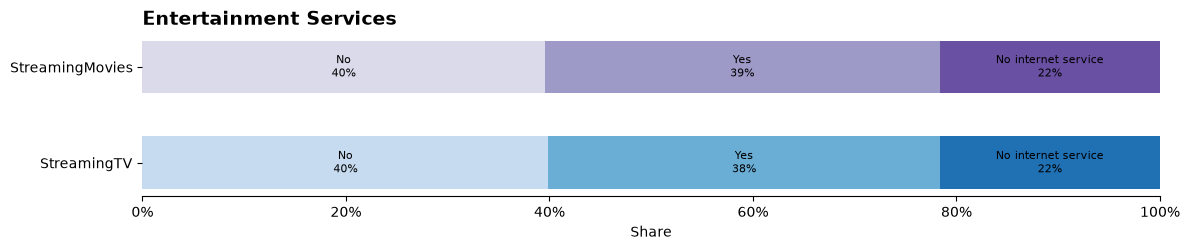

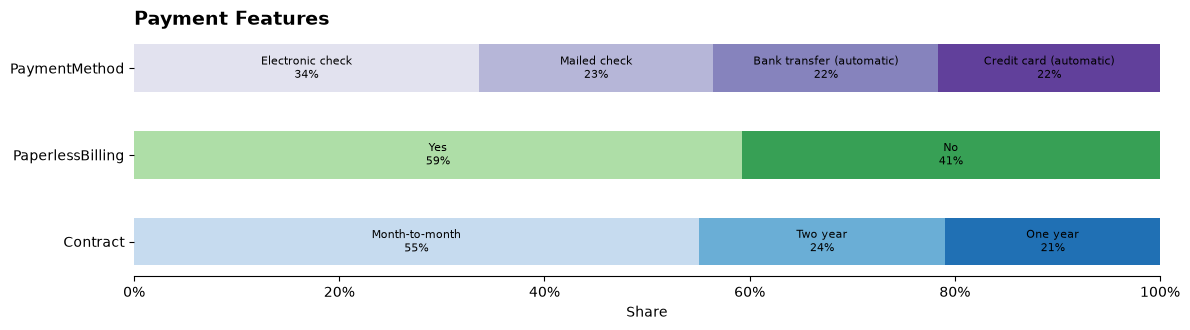

In [68]:
# --------------------------------------------------
# 2. Give each feature its own base color
# --------------------------------------------------

feature_colors = {
    'gender': 'Blues',
    'SeniorCitizen': 'Greens',
    'Partner': 'Purples',
    'Dependents': 'Oranges',

    'PhoneService': 'Blues',
    'MultipleLines': 'Greens',
    'InternetService': 'Purples',

    'OnlineSecurity': 'Blues',
    'OnlineBackup': 'Greens',
    'DeviceProtection': 'Purples',
    'TechSupport': 'Oranges',

    'StreamingTV': 'Blues',
    'StreamingMovies': 'Purples',

    'Contract': 'Blues',
    'PaperlessBilling': 'Greens',
    'PaymentMethod': 'Purples'
}


# --------------------------------------------------
# 3. Plotting function
# --------------------------------------------------

def plot_categorical_segment(df, features, title):

    fig, ax = plt.subplots(
        figsize=(12, 0.8 * len(features) + 1)
    )

    for i, feature in enumerate(features):

        # Proportion of each category
        proportions = df[feature].value_counts(
            normalize=True
        )

        # Create a monochromatic palette for THIS feature
        palette = sns.color_palette(
            feature_colors[feature],
            n_colors=len(proportions)
        )

        left = 0

        # Draw each category
        for color, (category, proportion) in zip(
            palette,
            proportions.items()
        ):

            ax.barh(
                i,
                proportion,
                left=left,
                height=0.55,
                color=color
            )

            # Label inside the segment
            if proportion >= 0.05:

                ax.text(
                    left + proportion / 2,
                    i,
                    f"{category}\n{proportion:.0%}",
                    ha="center",
                    va="center",
                    fontsize=8
                )

            left += proportion


    # --------------------------------------------------
    # 4. Formatting
    # --------------------------------------------------

    # Feature names on y-axis
    ax.set_yticks(range(len(features)))
    ax.set_yticklabels(features)

    # 0–100% x-axis
    ax.set_xlim(0, 1)

    ax.xaxis.set_major_formatter(
        plt.FuncFormatter(
            lambda x, _: f"{x:.0%}"
        )
    )

    ax.set_xlabel("Share")
    ax.set_ylabel("")

    # Figure title
    ax.set_title(
        title,
        loc="left",
        fontsize=14,
        fontweight="bold"
    )

    # Cleaner business-report appearance
    sns.despine(
        ax=ax,
        left=True
    )

    plt.tight_layout()
    plt.show()


# --------------------------------------------------
# 5. Generate one figure per feature segment
# --------------------------------------------------

for segment, features in feature_segments.items():

    plot_categorical_segment(
        df,
        features,
        segment
    )

In [69]:
df['Churn'].value_counts(normalize=True)

Churn
No     0.73463
Yes    0.26537
Name: proportion, dtype: float64

In [70]:
df['Status']= np.where(df['Churn']== 'No', 'Active','Inactive')
df['Status'].value_counts(normalize=True)



Status
Active      0.73463
Inactive    0.26537
Name: proportion, dtype: float64

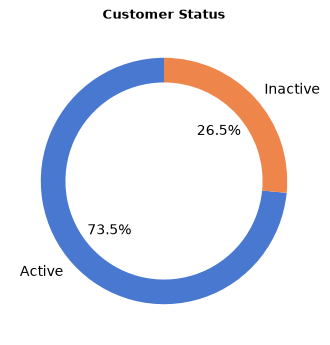

In [71]:
status_counts = df['Status'].value_counts()

colors = sns.color_palette("muted", 2)

plt.figure(figsize=(4,4))

plt.pie(
    status_counts,
    labels=status_counts.index,
    autopct='%1.1f%%',
    startangle=90,
    colors=colors,
    wedgeprops={'width': 0.2}
)

plt.title(
    'Customer Status',
    fontsize=9,
    fontweight='bold'
)

plt.show()

In [72]:
df['TotalCharges'] = pd.to_numeric(
    df['TotalCharges'],
    errors='coerce'
)

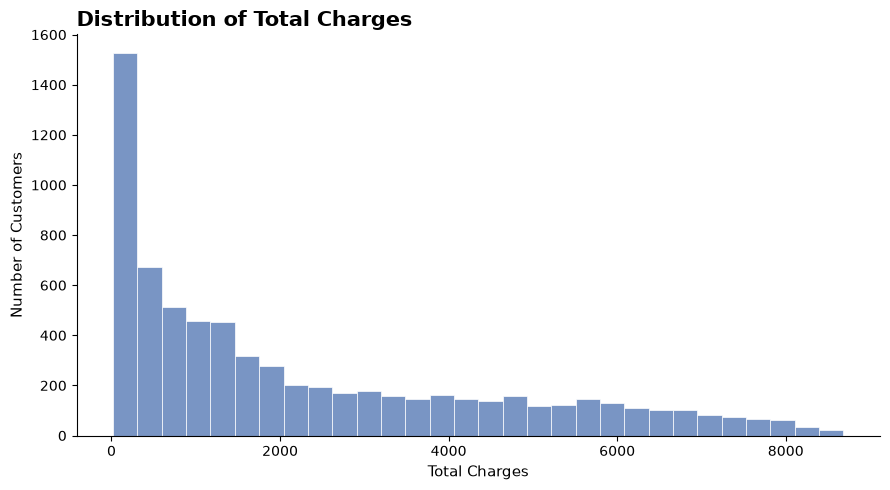

In [73]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x='TotalCharges',
    bins=30,
    color=sns.color_palette("deep")[0],
    edgecolor='white',
    linewidth=0.5
)

plt.title(
    'Distribution of Total Charges',
    fontsize=15,
    fontweight='bold',
    loc='left'
)

plt.xlabel('Total Charges', fontsize=11)
plt.ylabel('Number of Customers', fontsize=11)

sns.despine()

plt.tight_layout()
plt.show()

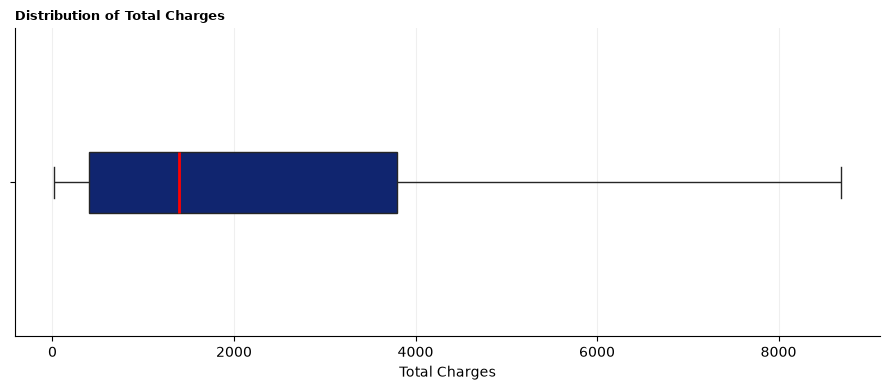

In [74]:
plt.figure(figsize=(9, 4))

sns.boxplot(
    data=df,
    x='TotalCharges',
    color=sns.color_palette("dark")[0],
    width=0.2,
    linewidth=1,
    medianprops={'color': 'red', 'linewidth': 2},
    
)

plt.title(
    'Distribution of Total Charges',
    fontsize=9,
    fontweight='bold',
    loc='left'
)

plt.xlabel('Total Charges')
plt.ylabel('')

plt.grid(
    axis='x',
    alpha=0.2
)

sns.despine()

plt.tight_layout()
plt.show()

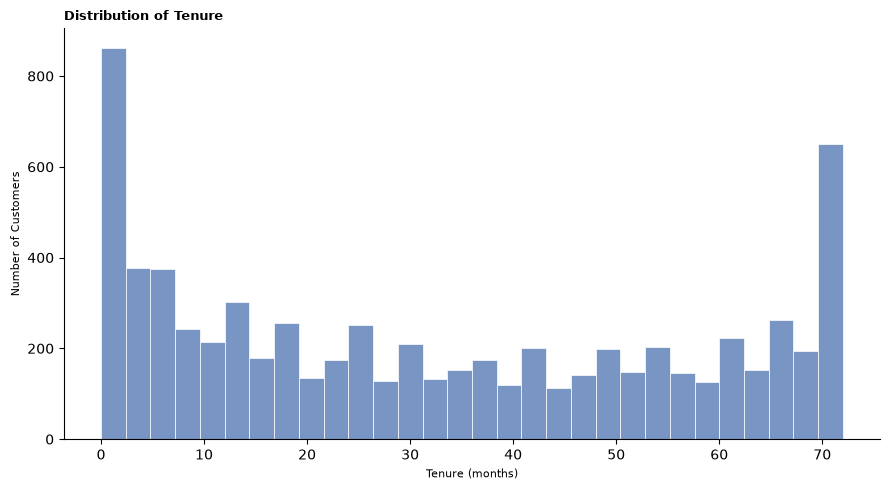

In [75]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x='tenure',
    bins=30,
    color=sns.color_palette("deep")[0],
    edgecolor='white',
    linewidth=0.5
)

plt.title(
    'Distribution of Tenure',
    fontsize=9,
    fontweight='bold',
    loc='left'
)

plt.xlabel('Tenure (months)', fontsize=8)
plt.ylabel('Number of Customers', fontsize=8)

sns.despine()

plt.tight_layout()
plt.show()

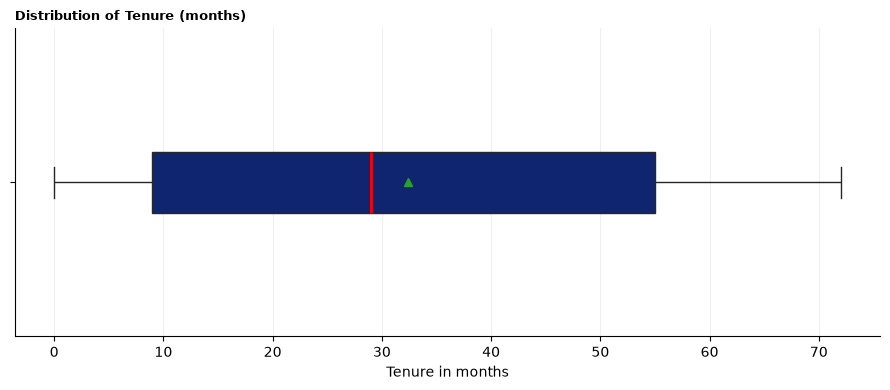

In [76]:
plt.figure(figsize=(9, 4))

sns.boxplot(
    data=df,
    x='tenure',
    color=sns.color_palette("dark")[0],
    width=0.2,
    linewidth=1,
    medianprops={'color': 'red', 'linewidth': 2},
    showmeans= True
    
)

plt.title(
    'Distribution of Tenure (months)',
    fontsize=9,
    fontweight='bold',
    loc='left'
)

plt.xlabel('Tenure in months')
plt.ylabel('')

plt.grid(
    axis='x',
    alpha=0.2
)

sns.despine()

plt.tight_layout()
plt.show()

In [77]:
all_stats = []

# --------------------------------------------------
# Overall benchmarks
# --------------------------------------------------

tenure_benchmark = df['tenure'].median()

churn_benchmark = (
    (df['Churn'] == 'Yes').mean() * 100
)

# --------------------------------------------------
# ALL CUSTOMERS row
# --------------------------------------------------

overall_stats = pd.Series({
    'Min': df['tenure'].min(),
    'Q1': df['tenure'].quantile(0.25),
    'Median': df['tenure'].median(),
    'Mean': df['tenure'].mean(),
    'Q3': df['tenure'].quantile(0.75),
    'Max': df['tenure'].max(),
    'Churn %': churn_benchmark,
    'Tenure Index': 100,
    'Churn Index': 100
})

overall_stats['Feature'] = 'ALL'
overall_stats['Category'] = 'ALL'

# Put Feature and Category first
overall_stats = overall_stats[
    [
        'Feature',
        'Category',
        'Min',
        'Q1',
        'Median',
        'Mean',
        'Q3',
        'Max',
        'Churn %',
        'Tenure Index',
        'Churn Index'
    ]
]

# Add overall row
all_stats.append(
    overall_stats.to_frame().T
)

# --------------------------------------------------
# Feature-level statistics
# --------------------------------------------------

for feature in categorical_features:

    stats = df.groupby(feature)['tenure'].agg(
        Min='min',
        Q1=lambda x: x.quantile(0.25),
        Median='median',
        Mean='mean',
        Q3=lambda x: x.quantile(0.75),
        Max='max'
    )

    # Calculate churn %
    churn_rate = df.groupby(feature)['Churn'].apply(
        lambda x: (x == 'Yes').mean() * 100
    )

    # Add churn rate
    stats['Churn %'] = churn_rate

    # Add Tenure Index
    stats['Tenure Index'] = (
        stats['Median'] / tenure_benchmark
    ) * 100

    # Add Churn Index
    stats['Churn Index'] = (
        stats['Churn %'] / churn_benchmark
    ) * 100

    # Add feature and category columns
    stats.insert(0, 'Feature', feature)
    stats.insert(1, 'Category', stats.index)

    all_stats.append(
        stats.reset_index(drop=True)
    )

# --------------------------------------------------
# Combine everything
# --------------------------------------------------

tenure_summary = pd.concat(
    all_stats,
    ignore_index=True
)

# --------------------------------------------------
# Round results
# --------------------------------------------------

tenure_summary = tenure_summary.round({
    'Min': 1,
    'Q1': 1,
    'Median': 1,
    'Mean': 1,
    'Q3': 1,
    'Max': 1,
    'Churn %': 1,
    'Tenure Index': 1,
    'Churn Index': 1
})

tenure_summary

,Feature,Category,Min,Q1,Median,Mean,Q3,Max,Churn %,Tenure Index,Churn Index
0,ALL,ALL,0.0,9.0,29.0,32.371149,55.0,72.0,26.536987,100.0,100.0
1,gender,Female,0,9.0,29.0,32.244553,55.0,72,26.920872,100.0,101.446602
2,gender,Male,0,9.0,29.0,32.495359,56.0,72,26.160338,100.0,98.580662
3,SeniorCitizen,0,0,9.0,28.0,32.192171,55.0,72,23.606168,96.551724,88.955722
4,SeniorCitizen,1,1,10.0,31.0,33.295972,56.0,72,41.681261,106.896552,157.06855
5,Partner,No,0,4.0,16.0,23.357869,39.0,72,32.957979,55.172414,124.196385
6,Partner,Yes,0,21.0,46.0,42.017637,65.0,72,19.664903,158.62069,74.103752
7,Dependents,No,1,7.0,25.0,29.806,52.0,72,31.27914,86.206897,117.869977
8,Dependents,Yes,0,16.0,39.0,38.368246,62.0,72,15.450237,134.482759,58.221519
9,PhoneService,No,0,8.0,29.0,31.737537,53.0,72,24.926686,100.0,93.931863


### Benchmark Index

To compare each customer category against the overall customer base, 
benchmark indices are calculated as:

$$
\text{Index} =
\frac{\text{Category Value}}
{\text{Overall Benchmark}}
\times 100
$$

For **Tenure Index**, the overall median tenure is used as the benchmark:

$$
\text{Tenure Index} =
\frac{\text{Category Median Tenure}}
{\text{Overall Median Tenure}}
\times 100
$$

For **Churn Index**, the overall churn rate is used as the benchmark:

$$
\text{Churn Index} =
\frac{\text{Category Churn Rate}}
{\text{Overall Churn Rate}}
\times 100
$$

An index of **100** indicates that the category is exactly at the overall
benchmark. Values **above 100** indicate over-indexing, while values
**below 100** indicate under-indexing.

For Tenure, a higher index indicates longer-than-average customer tenure.
For Churn, a higher index indicates higher-than-average churn.

In [78]:
import plotly.io as pio

In [79]:
import plotly.graph_objects as go

# ---------------------------------------
# Categories to highlight
# ---------------------------------------

highlight = [
    ('InternetService', 'Fiber optic'),
    ('InternetService', 'DSL'),
    ('Contract', 'Month-to-month'),
    ('Contract', 'Two year'),
    ('PaymentMethod', 'Electronic check'),
    ('SeniorCitizen', '1'),
    ('InternetService', 'No'),
    ('OnlineSecurity', 'Yes')
]

# ---------------------------------------
# Create highlight flag
# ---------------------------------------

tenure_summary['Highlight'] = tenure_summary.apply(
    lambda row: (
        row['Feature'],
        str(row['Category'])
    ) in highlight,
    axis=1
)

# ---------------------------------------
# Split data
# ---------------------------------------

normal = tenure_summary[
    ~tenure_summary['Highlight']
].copy()

highlighted = tenure_summary[
    tenure_summary['Highlight']
].copy()

# ---------------------------------------
# Hover text
# ---------------------------------------

def make_hover(df):
    return [
        f"<b>{feature}: {category}</b>"
        f"<br>Median tenure: {median:.1f} months"
        f"<br>Churn: {churn:.1f}%"
        f"<br>Tenure Index: {tenure_index:.1f}"
        f"<br>Churn Index: {churn_index:.1f}"
        for feature, category, median, churn, tenure_index, churn_index
        in zip(
            df['Feature'],
            df['Category'],
            df['Median'],
            df['Churn %'],
            df['Tenure Index'],
            df['Churn Index']
        )
    ]

normal_hover = make_hover(normal)
highlight_hover = make_hover(highlighted)

# ---------------------------------------
# Create figure
# ---------------------------------------

fig = go.Figure()

# All normal points
fig.add_trace(
    go.Scatter(
        x=normal['Tenure Index'],
        y=normal['Churn Index'],
        mode='markers',
        marker=dict(
            size=9,
            color='steelblue',
            opacity=0.6
        ),
        text=normal_hover,
        hovertemplate='%{text}<extra></extra>',
        name='Other categories'
    )
)

# Highlighted points
fig.add_trace(
    go.Scatter(
        x=highlighted['Tenure Index'],
        y=highlighted['Churn Index'],
        mode='markers+text',
        marker=dict(
            size=12,
            color='red'
        ),

        text=[
            f"{feature}: {category}"
            for feature, category
            in zip(
                highlighted['Feature'],
                highlighted['Category']
            )
        ],




        textposition=[
            'top right',
            'bottom right',
            'top left',
            'bottom right',
            'top right',
            'middle left',
            'bottom left',
            'top left'
        ],
        textfont=dict(
            size=10,
            color='red'
        ),



        customdata=highlight_hover,

        hovertemplate='%{customdata}<extra></extra>',

        name='Highlighted'
    )
)

# ---------------------------------------
# Benchmark lines
# ---------------------------------------

fig.add_hline(
    y=100,
    line_dash='dash',
    line_color='gray'
)

fig.add_vline(
    x=100,
    line_dash='dash',
    line_color='gray'
)

# ---------------------------------------
# Quadrant labels
# ---------------------------------------

fig.add_annotation(
    x=60,
    y=180,
    text='<b>SHORTER TENURE<br>HIGHER CHURN</b>',
    showarrow=False,
    font=dict(size=10, color='gray'),
    align='center'
)

fig.add_annotation(
    x=180,
    y=180,
    text='<b>LONGER TENURE<br>HIGHER CHURN</b>',
    showarrow=False,
    font=dict(size=10, color='gray'),
    align='center'
)

fig.add_annotation(
    x=60,
    y=40,
    text='<b>SHORTER TENURE<br>LOWER CHURN</b>',
    showarrow=False,
    font=dict(size=10, color='gray'),
    align='center'
)

fig.add_annotation(
    x=180,
    y=40,
    text='<b>LONGER TENURE<br>LOWER CHURN</b>',
    showarrow=False,
    font=dict(size=10, color='gray'),
    align='center'
)
# ---------------------------------------
# Layout
# ---------------------------------------

fig.update_layout(
    title='Customer Categories: Tenure vs Churn Index',
    xaxis_title='Tenure Index (100 = benchmark)',
    yaxis_title='Churn Index (100 = benchmark)',
    template='plotly_white',
    width=1100,
    height=750
)

fig.show()

Other findings. Source - tenure_summary df + Excel

![Deviation in Churn](../documentation/images/deviation-in-churn.png)

![Median Tenure by Families](../documentation/images/Median-tenure-families.png)

![Median Tenure by Security](../documentation/images/median-tenure-security.png)

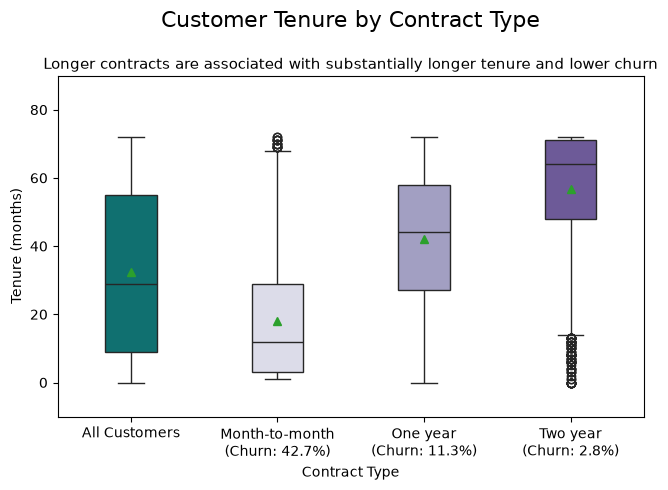

In [81]:
churn_rates = (
    df.groupby('Contract')['Churn']
    .apply(lambda x: (x == 'Yes').mean() * 100)
)

order = ['All Customers', 'Month-to-month', 'One year', 'Two year']

labels = [
    'All Customers',
    f"Month-to-month\n(Churn: {churn_rates['Month-to-month']:.1f}%)",
    f"One year\n(Churn: {churn_rates['One year']:.1f}%)",
    f"Two year\n(Churn: {churn_rates['Two year']:.1f}%)"
]

# Create a copy with an "All Customers" category
plot_df = df[['Contract', 'tenure']].copy()

plot_df.loc[:, 'Contract'] = plot_df['Contract'].astype(str)

all_customers = df[['tenure']].copy()
all_customers['Contract'] = 'All Customers'

plot_df = pd.concat(
    [all_customers, plot_df],
    ignore_index=True
)

plt.figure(figsize=(7, 5))

# Draw the boxes separately so we can control the colors
ax = sns.boxplot(
    data=plot_df,
    x='Contract',
    y='tenure',
    order=order,
    width=0.35,
    showmeans=True,
    showfliers=True,
    hue='Contract',
    palette={
        'All Customers': 'teal',
        'Month-to-month': sns.color_palette('Purples', 3)[0],
        'One year': sns.color_palette('Purples', 3)[1],
        'Two year': sns.color_palette('Purples', 3)[2]
    },
    legend=False
)

ax.set_xticks(range(len(order)))
ax.set_xticklabels(labels)

ax.set_xlabel('Contract Type')
ax.set_ylabel('Tenure (months)')


# Give outliers some space above the plot
ax.set_ylim(-10, 90)

ax.set_title(
    'Customer Tenure by Contract Type',
    fontsize=16,
    pad=35
)

ax.text(
    0.5, 1.02,
    'Longer contracts are associated with substantially longer tenure and lower churn',
    transform=ax.transAxes,
    ha='center',
    fontsize=11
)

plt.tight_layout()
plt.show()

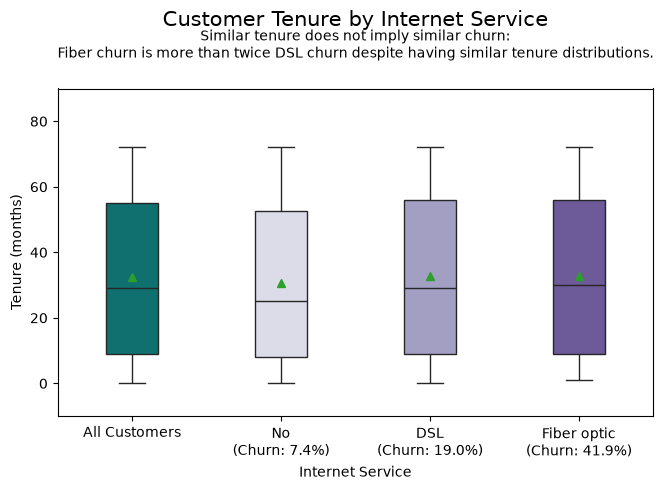

In [82]:
# Create a copy with an "All Customers" category
plot_df = df[['InternetService', 'tenure']].copy()

plot_df.loc[:, 'InternetService'] = plot_df['InternetService'].astype(str)

all_customers = df[['tenure']].copy()
all_customers['InternetService'] = 'All Customers'

plot_df = pd.concat(
    [all_customers, plot_df],
    ignore_index=True
)

# Order
order = ['All Customers', 'No', 'DSL', 'Fiber optic']

plt.figure(figsize=(7, 5))

# Draw the boxes with controlled colors
ax = sns.boxplot(
    data=plot_df,
    x='InternetService',
    y='tenure',
    order=order,
    width=0.35,
    showmeans=True,
    showfliers=True,
    hue='InternetService',
    palette={
        'All Customers': 'teal',
        'No': sns.color_palette('Purples', 3)[0],
        'DSL': sns.color_palette('Purples', 3)[1],
        'Fiber optic': sns.color_palette('Purples', 3)[2]
    },
    legend=False
)

# Churn rates
churn_rates = (
    df.groupby('InternetService')['Churn']
    .apply(lambda x: (x == 'Yes').mean() * 100)
)

labels = [
    'All Customers',
    f"No\n(Churn: {churn_rates['No']:.1f}%)",
    f"DSL\n(Churn: {churn_rates['DSL']:.1f}%)",
    f"Fiber optic\n(Churn: {churn_rates['Fiber optic']:.1f}%)"
]

ax.set_xticks(range(len(order)))
ax.set_xticklabels(labels)

ax.set_xlabel('Internet Service')
ax.set_ylabel('Tenure (months)')

# Title
ax.set_title(
    'Customer Tenure by Internet Service',
    fontsize=15,
    pad=45
)

# Observation
ax.text(
    0.5, 1.08,
    'Similar tenure does not imply similar churn:\n'
    'Fiber churn is more than twice DSL churn despite having similar tenure distributions.',
    transform=ax.transAxes,
    ha='center',
    va='bottom',
    fontsize=10
)

# Give outliers some space
ax.set_ylim(-10, 90)

plt.tight_layout()
plt.show()